# Clustering in scikit-learn 

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

#Load iris dataset into dataframe
iris_df = sns.load_dataset("iris")
print(pd.__version__)

2.2.3


In [28]:
#Show data frame content
iris_df

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [29]:
#create additional numerical variable for species
codes = {'setosa':0, 'versicolor':1, 'virginica':2}
iris_df['species_num'] = iris_df['species'].map(codes)

In [30]:
#Show descriptive statistics of data frame
iris_df.describe()

,sepal_length,sepal_width,petal_length,petal_width,species_num
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


# Data Exploration

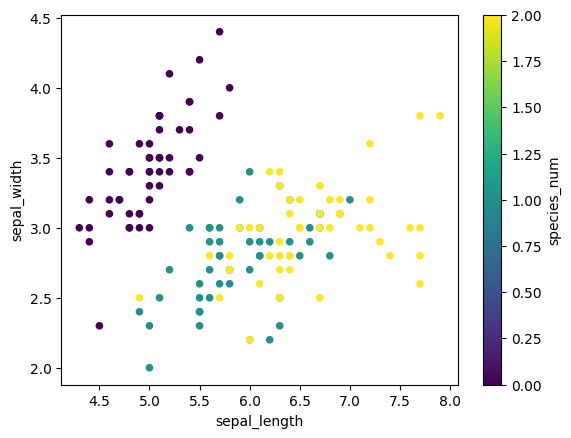

In [31]:
#Create pandas scatterplot 
ax1=iris_df.plot.scatter('sepal_length', 'sepal_width', c='species_num',colormap='viridis')
plt.show()

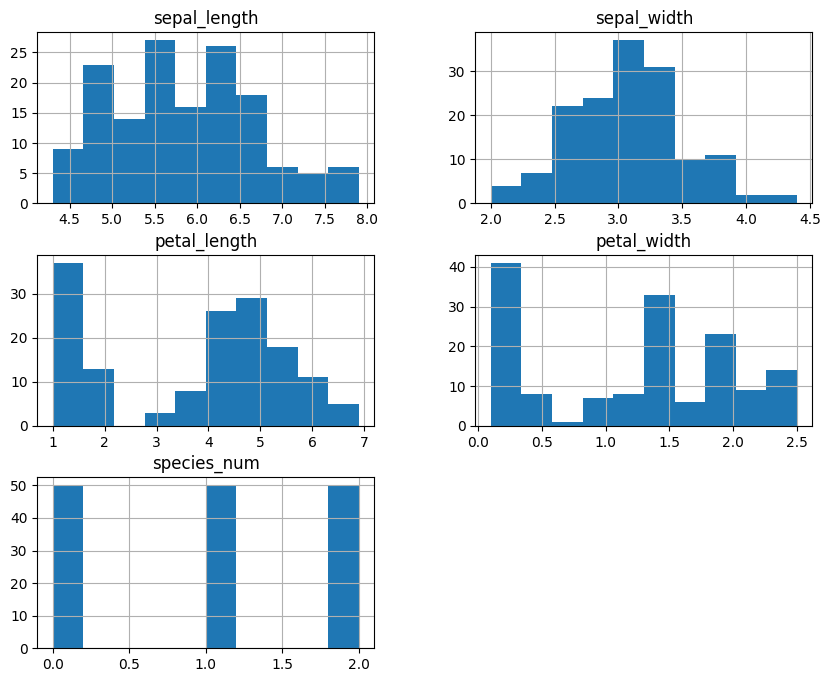

In [32]:
#Create histograms for the numerical variables using the dataframe method "hist"
#use figsize=(10,5) and a layout of 3 rows and 2 columns
hist = iris_df.hist(figsize=(10,8), layout=(3,2))

# Data Preparation
Clustering using distance-based similarity measures works better with normalized values

In [33]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

#fit iris features using scaler
scaler.fit(iris_df.iloc[:,:4])

#transform iris_features to normalized value range
iris_features_normed=scaler.transform(iris_df.iloc[:,:4])

#show transformed values
iris_features_normed

array([[0.22222222, 0.625     , 0.06779661, 0.04166667],
       [0.16666667, 0.41666667, 0.06779661, 0.04166667],
       [0.11111111, 0.5       , 0.05084746, 0.04166667],
       [0.08333333, 0.45833333, 0.08474576, 0.04166667],
       [0.19444444, 0.66666667, 0.06779661, 0.04166667],
       [0.30555556, 0.79166667, 0.11864407, 0.125     ],
       [0.08333333, 0.58333333, 0.06779661, 0.08333333],
       [0.19444444, 0.58333333, 0.08474576, 0.04166667],
       [0.02777778, 0.375     , 0.06779661, 0.04166667],
       [0.16666667, 0.45833333, 0.08474576, 0.        ],
       [0.30555556, 0.70833333, 0.08474576, 0.04166667],
       [0.13888889, 0.58333333, 0.10169492, 0.04166667],
       [0.13888889, 0.41666667, 0.06779661, 0.        ],
       [0.        , 0.41666667, 0.01694915, 0.        ],
       [0.41666667, 0.83333333, 0.03389831, 0.04166667],
       [0.38888889, 1.        , 0.08474576, 0.125     ],
       [0.30555556, 0.79166667, 0.05084746, 0.125     ],
       [0.22222222, 0.625     ,

In [34]:
#reconstruct data frame with normed features and label
iris_normed_df=pd.DataFrame(iris_features_normed,columns=iris_df.columns[:4])
iris_normed_df['label']=iris_df['species']
iris_normed_df

,sepal_length,sepal_width,petal_length,petal_width,label
0,0.222222,0.625000,0.067797,0.041667,setosa
1,0.166667,0.416667,0.067797,0.041667,setosa
2,0.111111,0.500000,0.050847,0.041667,setosa
3,0.083333,0.458333,0.084746,0.041667,setosa
4,0.194444,0.666667,0.067797,0.041667,setosa
...,...,...,...,...,...
145,0.666667,0.416667,0.711864,0.916667,virginica
146,0.555556,0.208333,0.677966,0.750000,virginica
147,0.611111,0.416667,0.711864,0.791667,virginica
148,0.527778,0.583333,0.745763,0.916667,virginica


# Model Building

### K-Means Clustering

In [35]:
#K-Means Clustering
from sklearn.cluster import KMeans

#Store data frame features in an own data frame
features=iris_normed_df.loc[:,'sepal_length':'petal_width']
#Intitialize and fit kmeans-Clustering with k=3
kmeans = KMeans(n_clusters=3, random_state=0).fit(features)

#Print cluster labels and centers using the according attributes of your kmeans model
print("Cluster labels: ",kmeans.labels_)
print("Cluster centers: \n",kmeans.cluster_centers_)

Cluster labels:  [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 0 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 2 2 2 2 2 0 2 0 2 2 2 2 2 2 2 2 2 2 2 0 0 2 2 2 2 2 2 2 0 2 2 2 2 2
 2 2]
Cluster centers: 
 [[0.41203704 0.27690972 0.55896893 0.52083333]
 [0.19611111 0.595      0.07830508 0.06083333]
 [0.66773504 0.44310897 0.7571708  0.78205128]]


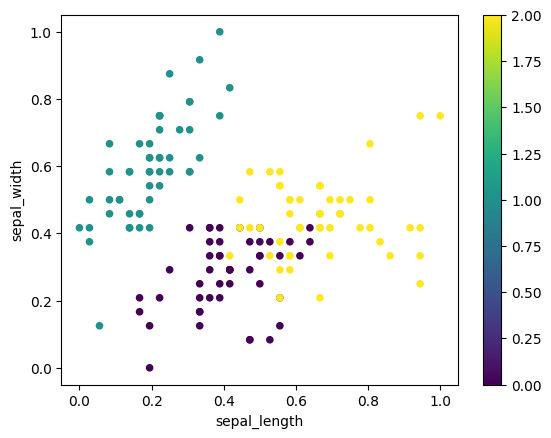

In [36]:
#Create a pandas scatterplot using seaborn, similar to exploration task
#x and y positions should hold sepal information, hue should be the kmeans labels and style the actual labels
ax1=iris_normed_df.plot.scatter('sepal_length', 'sepal_width', c=kmeans.labels_,colormap='viridis')
plt.show()

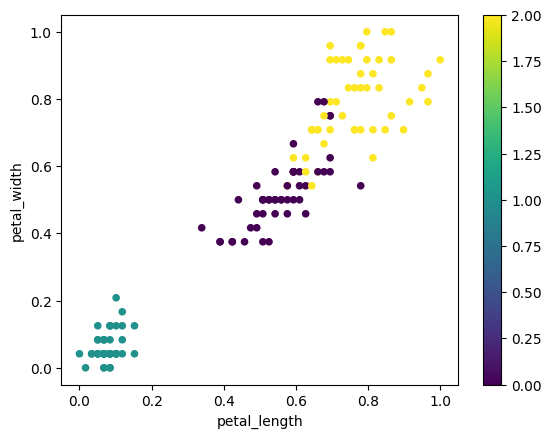

In [37]:
ax1=iris_normed_df.plot.scatter('petal_length', 'petal_width', c=kmeans.labels_,colormap='viridis')
plt.show()

In [40]:
from sklearn.cluster import DBSCAN
db_scan = DBSCAN(eps=0.2).fit(features)

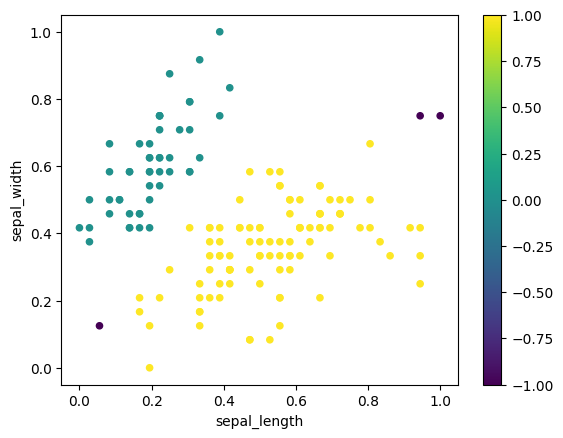

In [41]:
ax1=iris_normed_df.plot.scatter('sepal_length', 'sepal_width', c=db_scan.labels_,colormap='viridis')
plt.show()

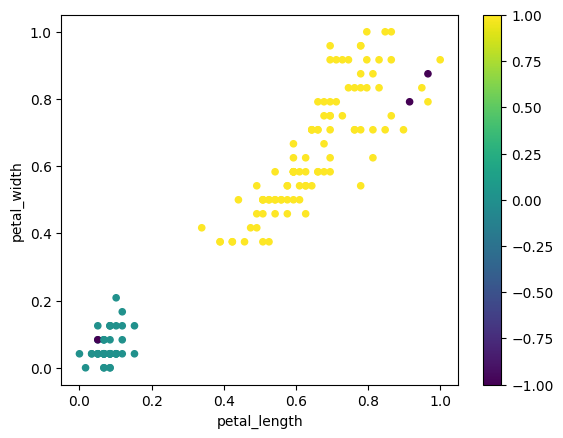

In [42]:
ax1=iris_normed_df.plot.scatter('petal_length', 'petal_width', c=db_scan.labels_,colormap='viridis')
plt.show()

Change the hyper-parameter k and check the effect on the clustering result!